<a href="https://colab.research.google.com/github/Oli-via123/AI-ML-Practice-and-Projects/blob/main/AI%20and%20ML%20Practice/Computer%20Vision/Comp_vision.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Computer Vision: CNNs & Transfer Learning with ResNet

**Learning objectives**
- Build and train a CNN from scratch, and see where it plateaus
- Understand transfer learning: feature extraction vs. fine-tuning
- Correctly preprocess images for a pretrained backbone (this is where most bugs live)
- Recognize and avoid the pitfalls that break this exact kind of pipeline in the real world
- Evaluate and compare models honestly

**How to use this notebook**: Use this as code-along and run each cells accordingly


## 1. Setup & Imports

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models, regularizers
from tensorflow.keras.layers import Input
from tensorflow.keras.datasets import cifar10
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet import preprocess_input
from sklearn.metrics import classification_report, confusion_matrix

# Reproducibility. Without this, you won't be to know if fine-tuning actually help
# you can't tell a real improvement from run-to-run noise.
SEED = 234
tf.random.set_seed(SEED)
np.random.seed(SEED)

print("TensorFlow:", tf.__version__)
print("GPU available:", len(tf.config.list_physical_devices('GPU')) > 0)


TensorFlow: 2.20.0
GPU available: True


## 2. Load & Explore the Data

CIFAR-10: 60,000 32x32 RGB images across 10 balanced classes (50,000 train / 10,000 test).


In [ ]:
(x_train_full, y_train_full), (x_test, y_test) = cifar10.load_data()

class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer',
               'dog', 'frog', 'horse', 'ship', 'truck']

print("x_train_full:", x_train_full.shape, x_train_full.dtype)
print("x_test:      ", x_test.shape, x_test.dtype)

# Sanity-check the label balance before doing anything else.
unique, counts = np.unique(y_train_full, return_counts=True)
for cls, cnt in zip(unique, counts):
    print(f"{class_names[cls[0]] if hasattr(cls,'__len__') else class_names[cls]:12s} {cnt}")


x_train_full: (50000, 32, 32, 3) uint8
x_test:       (10000, 32, 32, 3) uint8
airplane     5000
automobile   5000
bird         5000
cat          5000
deer         5000
dog          5000
frog         5000
horse        5000
ship         5000
truck        5000


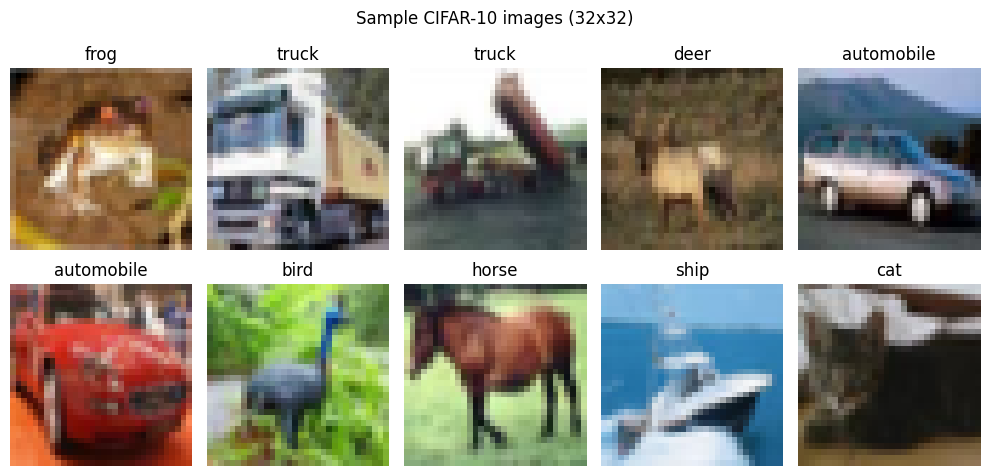

In [ ]:
# Visualize a few samples so we know what we're working with
fig, axes = plt.subplots(2, 5, figsize=(10, 5))
for i, ax in enumerate(axes.flat):
    ax.imshow(x_train_full[i])
    ax.set_title(class_names[int(y_train_full.flatten()[i])]) #ax.set_title(y_train_full.flatten()[i]) Use this instead if you want to view the numbel label
    ax.axis('off')
plt.suptitle("Sample CIFAR-10 images (32x32)")
plt.tight_layout()
plt.show()


### > Common mistake #1: using the test set as your validation set

It's tempting to pass `x_test`/`y_test` as `validation_data` during training, since you already
have it loaded. **Don't.** Every time you check validation loss to decide on early stopping, the
best checkpoint, or a learning-rate drop, you are indirectly fitting decisions to that data.
By the time you report a "test accuracy," it's no longer an honest estimate of generalization.
It's already been used to pick the model.

The way out: carve a validation set out of the **training** data. Keep the test set untouched until
the very last cell.


In [ ]:
# Carve a validation split out of the training set. The test set is not touched again
# until final evaluation.
VAL_SIZE = 5000

x_train, y_train = x_train_full[VAL_SIZE:], y_train_full[VAL_SIZE:]
x_val, y_val = x_train_full[:VAL_SIZE], y_train_full[:VAL_SIZE]

print("train:", x_train.shape)
print("val:  ", x_val.shape)
print("test: ", x_test.shape)

# Normalize to [0, 1] and one-hot encode labels
x_train_norm = x_train.astype('float32') / 255.0
x_val_norm = x_val.astype('float32') / 255.0
x_test_norm = x_test.astype('float32') / 255.0

y_train_oh = keras.utils.to_categorical(y_train, num_classes=10)
y_val_oh = keras.utils.to_categorical(y_val, num_classes=10)
y_test_oh = keras.utils.to_categorical(y_test, num_classes=10)


train: (45000, 32, 32, 3)
val:   (5000, 32, 32, 3)
test:  (10000, 32, 32, 3)


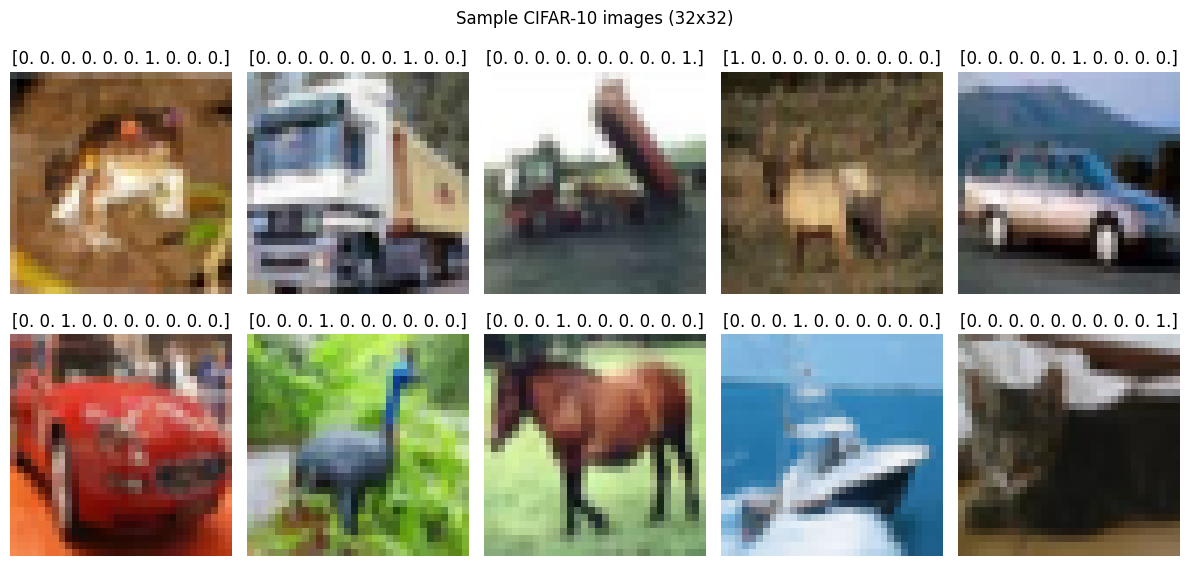

In [ ]:
# Visualize a few samples so we know what we're working with
fig, axes = plt.subplots(2, 5, figsize=(12, 6))
for i, ax in enumerate(axes.flat):
    ax.imshow(x_train_full[i])
    ax.set_title(y_train_oh[i])
    ax.axis('off')
plt.suptitle("Sample CIFAR-10 images (32x32)")
plt.tight_layout()
plt.show()


## 3. Baseline: A CNN Trained From Scratch

Before reaching for a pretrained backbone, always establish a from-scratch baseline. It tells you
how much transfer learning is actually buying you — and on a dataset this small (32x32 images),
that's not a given.


In [ ]:
def create_simple_cnn(input_shape=(32, 32, 3), num_classes=10):
    model = models.Sequential([
        layers.Input(shape=input_shape),
        layers.Conv2D(32, (3, 3), padding='same'),
        layers.BatchNormalization(),
        layers.Activation('relu'),
        layers.MaxPooling2D((2, 2)),
        layers.Dropout(0.2),

        layers.Conv2D(64, (3, 3), padding='same'),
        layers.BatchNormalization(),
        layers.Activation('relu'),
        layers.MaxPooling2D((2, 2)),
        layers.Dropout(0.3),

        layers.Conv2D(128, (3, 3), padding='same'),
        layers.BatchNormalization(),
        layers.Activation('relu'),
        layers.MaxPooling2D((2, 2)),
        layers.Dropout(0.4),

        layers.Flatten(),
        layers.Dense(512, activation='relu'),
        layers.Dropout(0.5),
        layers.Dense(num_classes, activation='softmax')
    ])
    return model

baseline_model = create_simple_cnn()
baseline_model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)
baseline_model.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_5 (Activation)       │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 512)            │     1,049,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         5,130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,148,362 (4.38 MB)

 Trainable params: 1,147,914 (4.38 MB)

 Non-trainable params: 448 (1.75 KB)

In [ ]:
baseline_callbacks = [
    keras.callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True),
]

baseline_history = baseline_model.fit(
    x_train_norm, y_train_oh,
    validation_data=(x_val_norm, y_val_oh),
    epochs=25,
    batch_size=64,
    callbacks=baseline_callbacks
)


Epoch 1/25
704/704 ━━━━━━━━━━━━━━━━━━━━ 15s 12ms/step - accuracy: 0.3446 - loss: 1.7895 - val_accuracy: 0.4922 - val_loss: 1.4082
Epoch 2/25
704/704 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.4685 - loss: 1.4481 - val_accuracy: 0.5540 - val_loss: 1.2223
Epoch 3/25
704/704 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.5294 - loss: 1.3052 - val_accuracy: 0.5922 - val_loss: 1.1262
Epoch 4/25
704/704 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.5699 - loss: 1.2102 - val_accuracy: 0.6448 - val_loss: 0.9981
Epoch 5/25
704/704 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.5930 - loss: 1.1399 - val_accuracy: 0.6578 - val_loss: 0.9520
Epoch 6/25
704/704 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.6155 - loss: 1.0933 - val_accuracy: 0.6870 - val_loss: 0.8748
Epoch 7/25
704/704 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.6316 - loss: 1.0487 - val_accuracy: 0.7072 - val_loss: 0.8236
Epoch 8/25
704/704 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.6483 - loss: 1.0095 - val_accuracy: 

In [ ]:
best_epoch = np.argmin(baseline_history.history['val_loss'])
print(f"Best epoch: {best_epoch + 1}")
print(f"Best val_loss: {baseline_history.history['val_loss'][best_epoch]:.4f}")
print(f"Best val_accuracy: {baseline_history.history['val_accuracy'][best_epoch]:.4f}")

Best epoch: 23
Best val_loss: 0.6326
Best val_accuracy: 0.7776


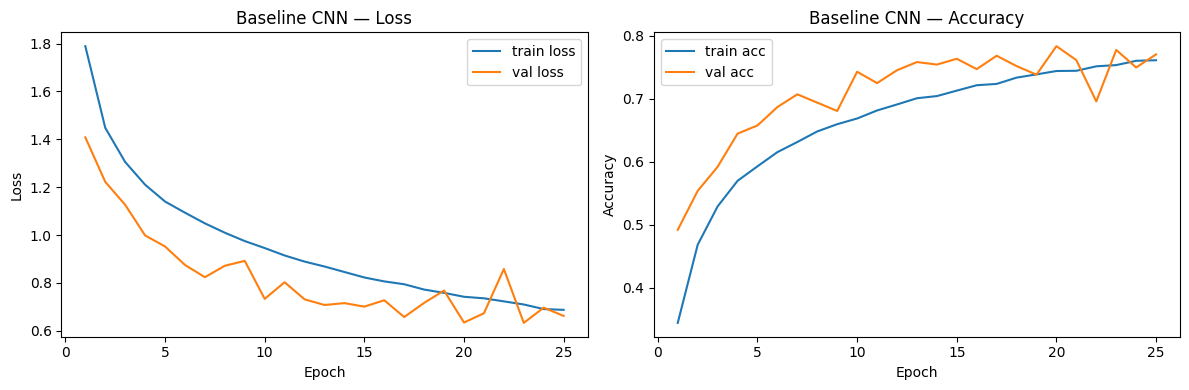

In [ ]:
def plot_training(history, title="Training Curves"):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    axes_range = range(1, len(history.history['loss']) + 1)

    # Loss
    axes[0].plot(axes_range, history.history['loss'], label='train loss')
    axes[0].plot(axes_range, history.history['val_loss'], label='val loss')
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('Loss')
    axes[0].set_title(f'{title} — Loss')
    axes[0].legend()

    # Accuracy
    axes[1].plot(axes_range, history.history['accuracy'], label='train acc')
    axes[1].plot(axes_range, history.history['val_accuracy'], label='val acc')
    axes[1].set_xlabel('Epoch')
    axes[1].set_ylabel('Accuracy')
    axes[1].set_title(f'{title} — Accuracy')
    axes[1].legend()

    plt.tight_layout()
    plt.show()

plot_training(baseline_history, "Baseline CNN")

### 3.1 Baseline Model Evaluation

Baseline CNN - Test Loss: 0.6636
Baseline CNN - Test Accuracy: 0.7765

Baseline CNN - Classification Report:
              precision    recall  f1-score   support

    airplane       0.87      0.71      0.78      1000
  automobile       0.87      0.93      0.90      1000
        bird       0.66      0.67      0.67      1000
         cat       0.61      0.62      0.62      1000
        deer       0.70      0.78      0.74      1000
         dog       0.78      0.60      0.68      1000
        frog       0.71      0.92      0.80      1000
       horse       0.84      0.79      0.82      1000
        ship       0.87      0.90      0.88      1000
       truck       0.91      0.84      0.87      1000

    accuracy                           0.78     10000
   macro avg       0.78      0.78      0.78     10000
weighted avg       0.78      0.78      0.78     10000



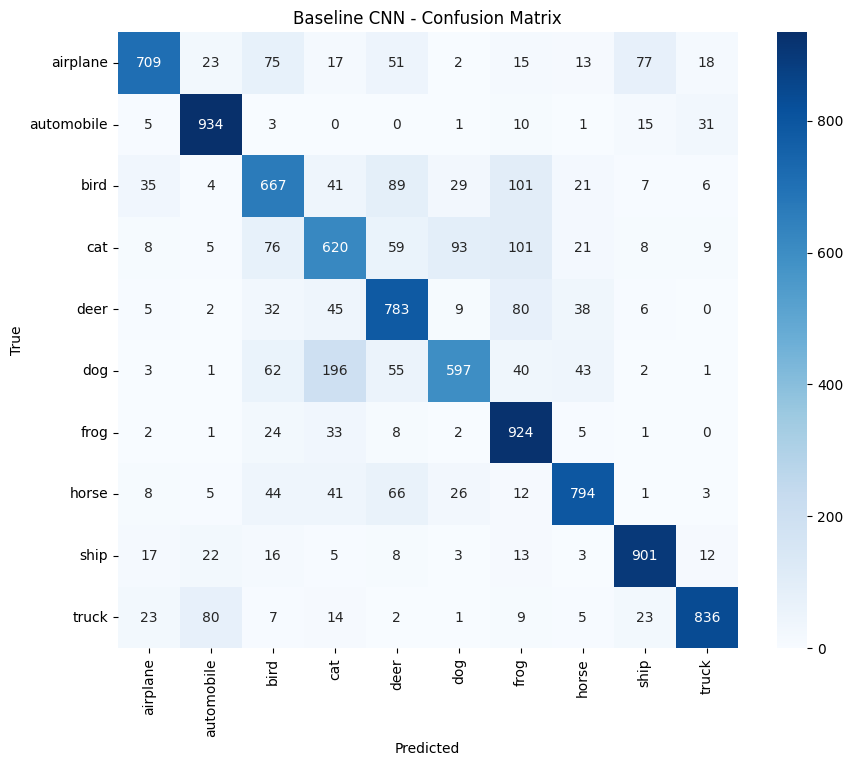

In [ ]:
def evaluate_model(model, x_test, y_test_oh, class_names, title="Model"):
    # Basic loss/accuracy
    test_loss, test_acc = model.evaluate(x_test, y_test_oh, verbose=0)
    print(f"{title} - Test Loss: {test_loss:.4f}")
    print(f"{title} - Test Accuracy: {test_acc:.4f}\n")

    # Get predictions
    y_pred_probs = model.predict(x_test, verbose=0)
    y_pred = np.argmax(y_pred_probs, axis=1)
    y_true = np.argmax(y_test_oh, axis=1)

    # Classification report
    print(f"{title} - Classification Report:")
    print(classification_report(y_true, y_pred, target_names=class_names))

    # Confusion matrix
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(10, 8))
    sns.heatmap(cm, annot=True, fmt='d', xticklabels=class_names,
                yticklabels=class_names, cmap='Blues')
    plt.xlabel('Predicted')
    plt.ylabel('True')
    plt.title(f'{title} - Confusion Matrix')
    plt.show()

    return {
        'test_loss': test_loss,
        'test_acc': test_acc,
        'y_pred': y_pred,
        'y_true': y_true,
        'confusion_matrix': cm
    }

results = evaluate_model(baseline_model, x_test_norm, y_test_oh, class_names, title="Baseline CNN")


## 4. Transfer Learning with ResNet50 — Feature Extraction

ResNet50 expects roughly 224x224 input and ImageNet-style preprocessing. CIFAR-10 images are
32x32, so they need to be upscaled — and this is exactly where the naive approach breaks.


### > Common mistake #2: resizing the whole dataset eagerly

A tempting first pass looks like this:

```python
def resize_images(images, target_size=(224, 224)):
    resized = np.zeros((images.shape[0], target_size[0], target_size[1], 3))  # float64 by default!
    for i in range(images.shape[0]):
        resized[i] = tf.image.resize(images[i], target_size)
    return resized
```

Do the math before running it: 50,000 images x 224 x 224 x 3 channels x 8 bytes (float64) is
**about 60 GB**, just for the training set, held fully in memory before training even starts.
On Colab/Kaggle this reliably crashes the kernel with an out-of-memory error.

The way to go is to resize **lazily, per batch**, using a `tf.data` pipeline so the images are only ever
materialized at 224x224 for the batch currently being processed, not the whole dataset at once.


In [ ]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

def make_dataset(images, labels_oh, training=False):
    ds = tf.data.Dataset.from_tensor_slices((images, labels_oh))

    def _prep(img, label):
        img = tf.image.resize(img, IMG_SIZE)
        # preprocess_input expects images in the model's native 0-255 range, so we
        # scale back up from the [0,1] normalization we did earlier -- once, here,
        # not twice. (Pitfall #3 below explains why this line is easy to get wrong.)
        img = img * 255.0
        img = preprocess_input(img)
        return img, label

    if training:
        ds = ds.shuffle(2000, seed=SEED)

    ds = ds.map(_prep, num_parallel_calls=tf.data.AUTOTUNE)

    if training:
        def _augment(img, label):
            img = tf.image.random_flip_left_right(img)
            return img, label
        ds = ds.map(_augment, num_parallel_calls=tf.data.AUTOTUNE)

    ds = ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
    return ds

train_ds = make_dataset(x_train_norm, y_train_oh, training=True)
val_ds = make_dataset(x_val_norm, y_val_oh, training=False)
test_ds = make_dataset(x_test_norm, y_test_oh, training=False)


### > Common mistake #3: double-scaling your pixel values

`preprocess_input` for ResNet expects pixel values on the model's native 0-255 scale (it does
its own ImageNet mean-subtraction internally) — **not** values already normalized to [0,1]. If you
normalize to [0,1] *and then* multiply by 255 *and then* call `preprocess_input`, you're fine
but if you multiply by 255 a value that was never in [0,1] to begin with, you'll silently corrupt
every image and the model will train on noise. Always know exactly what range your tensor is in at
each step. It's worth a one-line `print(img.numpy().min(), img.numpy().max())` the first time you
write a pipeline like this, just to confirm.


In [ ]:
def build_resnet_transfer_model(num_classes=10, trainable_base=False):
    base_model = ResNet50(weights='imagenet', include_top=False, input_shape=(224, 224, 3))
    base_model.trainable = trainable_base

    inputs = keras.Input(shape=(224, 224, 3))
    x = base_model(inputs, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(256, activation='relu')(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(num_classes, activation='softmax')(x)

    model = keras.Model(inputs, outputs)
    return model, base_model

resnet_model, resnet_base = build_resnet_transfer_model(trainable_base=False)
resnet_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)
resnet_model.summary()


Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,114,826 (91.99 MB)

 Trainable params: 527,114 (2.01 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

In [ ]:
feature_extraction_callbacks = [
    keras.callbacks.EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True),
    keras.callbacks.ModelCheckpoint('resnet_feature_extraction_best.keras',
                                     monitor='val_loss', save_best_only=True),
]

history_feature_extraction = resnet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=feature_extraction_callbacks
)


Epoch 1/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 96s 60ms/step - accuracy: 0.8488 - loss: 0.4443 - val_accuracy: 0.8966 - val_loss: 0.2904
Epoch 2/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 73s 52ms/step - accuracy: 0.8873 - loss: 0.3267 - val_accuracy: 0.8972 - val_loss: 0.2919
Epoch 3/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 73s 52ms/step - accuracy: 0.8998 - loss: 0.2875 - val_accuracy: 0.9066 - val_loss: 0.2726
Epoch 4/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 73s 52ms/step - accuracy: 0.9079 - loss: 0.2649 - val_accuracy: 0.9092 - val_loss: 0.2569
Epoch 5/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 75s 53ms/step - accuracy: 0.9110 - loss: 0.2497 - val_accuracy: 0.9164 - val_loss: 0.2518
Epoch 6/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 73s 52ms/step - accuracy: 0.9198 - loss: 0.2243 - val_accuracy: 0.9134 - val_loss: 0.2589
Epoch 7/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 75s 53ms/step - accuracy: 0.9250 - loss: 0.2100 - val_accuracy: 0.9170 - val_loss: 0.2467
Epoch 8/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 74s 52ms/step - accuracy: 0.9290 -

## 5. Fine-Tuning

So far, only the new head (Dense layers) has been trained the ResNet backbone stayed frozen.
This is "feature extraction": you're using ImageNet's learned features as it is.

Fine-tuning goes a step further: unfreeze some of the backbone's later layers (the ones that
encode higher-level, more task-specific features) and continue training with a **much lower**
learning rate. Using too high a learning rate here will wreck the pretrained weights in a couple of
batches; this is the single most common fine-tuning mistake.


In [ ]:
# Unfreeze the top block of ResNet50, keep earlier (more generic) layers frozen
resnet_base.trainable = True
FINE_TUNE_AT = len(resnet_base.layers) - 30  # unfreeze roughly the last 30 layers

for layer in resnet_base.layers[:FINE_TUNE_AT]:
    layer.trainable = False

# Recompile is required any time you change layer.trainable -- Keras won't pick it up otherwise
resnet_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),  # note: ~100x lower than phase 1
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

fine_tune_callbacks = [
    keras.callbacks.EarlyStopping(monitor='val_loss', patience=4, restore_best_weights=True),
    keras.callbacks.ModelCheckpoint('resnet_finetuned_best.keras',
                                     monitor='val_loss', save_best_only=True),
]

history_fine_tune = resnet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=fine_tune_callbacks
)


Epoch 1/15
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 135s 83ms/step - accuracy: 0.9229 - loss: 0.2254 - val_accuracy: 0.9334 - val_loss: 0.2010
Epoch 2/15
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 105s 74ms/step - accuracy: 0.9522 - loss: 0.1355 - val_accuracy: 0.9408 - val_loss: 0.1847
Epoch 3/15
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 103s 73ms/step - accuracy: 0.9674 - loss: 0.0960 - val_accuracy: 0.9420 - val_loss: 0.1887
Epoch 4/15
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 103s 73ms/step - accuracy: 0.9760 - loss: 0.0691 - val_accuracy: 0.9416 - val_loss: 0.1900
Epoch 5/15
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 103s 73ms/step - accuracy: 0.9833 - loss: 0.0501 - val_accuracy: 0.9448 - val_loss: 0.1848
Epoch 6/15
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 103s 73ms/step - accuracy: 0.9880 - loss: 0.0370 - val_accuracy: 0.9490 - val_loss: 0.1932


## 6. Evaluation

313/313 ━━━━━━━━━━━━━━━━━━━━ 24s 62ms/step
=== ResNet50 (fine-tuned) ===
              precision    recall  f1-score   support

    airplane       0.94      0.94      0.94      1000
  automobile       0.96      0.96      0.96      1000
        bird       0.93      0.92      0.93      1000
         cat       0.88      0.85      0.86      1000
        deer       0.89      0.93      0.91      1000
         dog       0.89      0.89      0.89      1000
        frog       0.95      0.96      0.95      1000
       horse       0.95      0.95      0.95      1000
        ship       0.95      0.96      0.95      1000
       truck       0.96      0.95      0.95      1000

    accuracy                           0.93     10000
   macro avg       0.93      0.93      0.93     10000
weighted avg       0.93      0.93      0.93     10000



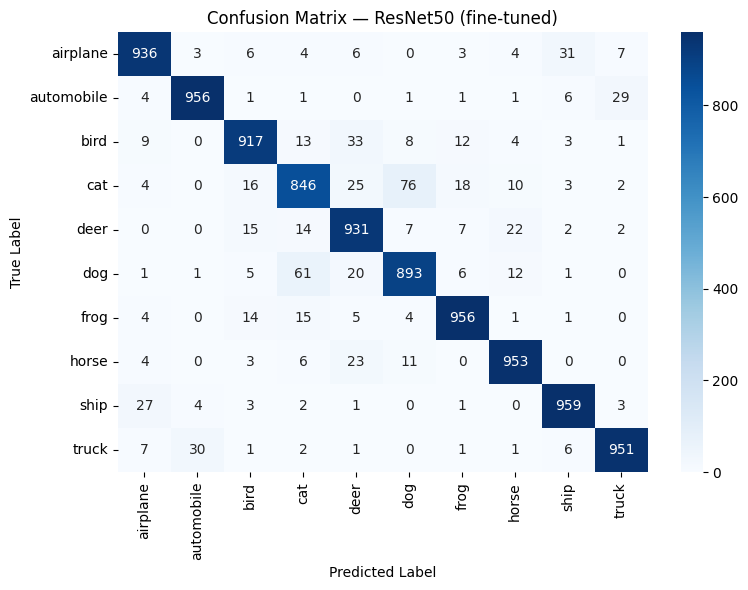

In [ ]:
def evaluate_and_report(model, dataset, y_true_int, title):
    y_pred_probs = model.predict(dataset)
    y_pred_classes = np.argmax(y_pred_probs, axis=1)

    print(f"=== {title} ===")
    print(classification_report(y_true_int, y_pred_classes, target_names=class_names))

    cm = confusion_matrix(y_true_int, y_pred_classes)
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=class_names, yticklabels=class_names)
    plt.title(f'Confusion Matrix — {title}')
    plt.ylabel('True Label')
    plt.xlabel('Predicted Label')
    plt.tight_layout()
    plt.show()

    return y_pred_classes

y_true_test = y_test.reshape(-1)
resnet_preds = evaluate_and_report(resnet_model, test_ds, y_true_test, "ResNet50 (fine-tuned)")


In [ ]:
_, resnet_test_acc = resnet_model.evaluate(test_ds, verbose=0)

print("Model comparison on held-out test set:")
print(f"  Baseline CNN (from scratch):       {baseline_test_acc:.4f}")
print(f"  ResNet50 (fine-tuned):             {resnet_test_acc:.4f}")


Model comparison on held-out test set:
  Baseline CNN (from scratch):       0.7765
  ResNet50 (fine-tuned):             0.9298


**Discussion for the group**: transfer learning doesn't automatically win. ResNet50 was pretrained
on 224x224 natural images; CIFAR-10 images are 32x32 upscaled to 224x224, which mostly adds
blur rather than real detail. Depending on your run, the gap between the baseline and the
fine-tuned ResNet may be smaller than people expect going in — that's a useful, realistic lesson
about when transfer learning helps most (limited data, similar-domain images) versus when a
smaller from-scratch model is perfectly competitive.


## 7. Saving the Model

In [ ]:
# .keras is the current native format (Keras 3). Avoid .h5 -- it's the legacy format
# and doesn't reliably round-trip custom objects or newer layer types.
resnet_model.save('cifar10_resnet_finetuned.keras')

reloaded_model = keras.models.load_model('cifar10_resnet_finetuned.keras')
print("Reloaded model matches original architecture:",
      len(reloaded_model.layers) == len(resnet_model.layers))


Reloaded model matches original architecture: True


## 8. Recap: Pitfalls Covered in This Notebook

| Pitfall | Symptom | Fix |
|---|---|---|
| Eagerly resizing the full dataset into a `float64` array | Kernel crash / OOM | Resize lazily per-batch with `tf.data` |
| Using the test set as `validation_data` | Inflated, dishonest test accuracy | Carve a separate validation split; touch test only once |
| Double-scaling pixel values before `preprocess_input` | Silent accuracy collapse, no error thrown | Know your tensor's value range at every step |
| Forgetting `.compile()` before `.fit()` | `RuntimeError` | Always compile after building or after changing `trainable` |
| Changing `layer.trainable` without recompiling | Fine-tuning silently does nothing | Recompile after any `trainable` change |
| Saving with `.h5` | Format deprecated, round-trip issues with newer layers | Use `.keras` |
| Undefined variables between cells | Works once interactively, fails on `Run All` | Always test with `Restart & Run All` before sharing |

## 9. Exercises

1. Swap `ResNet50` for `ResNet101` or `EfficientNetB0`. How does test accuracy and training time change?
2. Change `FINE_TUNE_AT` to unfreeze more or fewer layers. Where's the sweet spot?
3. Add `Mixup` or `CutMix` augmentation to the `tf.data` pipeline. Does it help the small-image, upscaled-input setting more or less than it would on native 224x224 photos?
4. Try training with a `tf.distribute.TPUStrategy()` scope if you're on a TPU runtime — what code has to change?
5. Deliberately reintroduce the double-scaling bug from Pitfall #3 and see how much test accuracy drops. It's a good way to build intuition for why silent bugs like this are worse than crashes.
